# Introduction to NumPy, pandas, and Matplotlib
**Chapter 01: Python — Lesson 07**

Use NumPy for numerical arrays, Matplotlib for visualization, and pandas for structured data.

**Prerequisites:** Python collections, indexing, functions, and module imports.  
**Environment:** Python 3.10 or newer with NumPy, pandas, Matplotlib, and a notebook kernel.

## Contents
1. Setup and imports
2. NumPy: arrays, inspection, indexing, statistics, broadcasting, and reshaping
3. Matplotlib: line, bar, and pie charts
4. pandas: Series, DataFrames, inspection, selection, and filtering
5. Missing values, sorting, and changing data
6. Saving and reading CSV files

All measurements, component names, and thresholds in this notebook are **synthetic teaching examples**, not real observations or engineering recommendations.
Run cells from top to bottom. No user input or external dataset is required.
The CSV section writes one example file in the kernel's current working directory.

## 1. Setup and imports
If the libraries are missing, install them in your repository's virtual environment
from **Windows CMD** at the repository root:

```cmd
.venv\Scripts\python.exe -m pip install numpy pandas matplotlib ipykernel
```

In VS Code, select the `.venv` interpreter using **Python: Select Interpreter**,
then separately choose the `.venv` **notebook kernel**. Restart the kernel after
installation if necessary. Colab normally provides these libraries already.

The aliases `np`, `pd`, and `plt` are widely used conventions. `Path` helps manage
file paths; `display` presents tables clearly in a notebook.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 2. NumPy: numerical arrays
A NumPy `ndarray` stores values in a multidimensional array with a single data type.
Unlike Python list repetition, numerical array operations usually act element by element.

### Create one-dimensional and two-dimensional arrays
A one-dimensional array has one axis. A two-dimensional array has two axes,
commonly interpreted as rows and columns. Nested rows must have matching lengths.

In [ ]:
one_dimensional_array = np.array([1, 2, 3, 4])
two_dimensional_array = np.array([[1, 2, 3], [4, 5, 6]])

print("1D array:", one_dimensional_array)
print("2D array:\n", two_dimensional_array)

1D array: [1 2 3 4]
2D array:
 [[1 2 3]
 [4 5 6]]


### Create special arrays
`np.zeros()` and `np.ones()` accept a shape and use floating-point values by default.
`np.arange(start, stop, step)` generates regularly spaced values, excluding `stop`.

In [ ]:
print("Zeros:\n", np.zeros((2, 3)))
print("Ones:\n", np.ones((2, 3)))
print("Range:", np.arange(0, 6, 2))

Zeros:
 [[0. 0. 0.]
 [0. 0. 0.]]
Ones:
 [[1. 1. 1.]
 [1. 1. 1.]]
Range: [0 2 4]


### Create and inspect power measurements
The six values below represent illustrative DC power measurements in watts,
recorded at six ordered measurement periods.

| Attribute | Meaning |
| --- | --- |
| `shape` | Length along each axis, as a tuple |
| `ndim` | Number of axes |
| `size` | Total number of elements |
| `dtype` | Element data type |

For a 1D array, `(6,)` means six elements along one axis, not six rows and one column.

In [ ]:
power_w = np.array([120.0, 180.0, 250.0, 310.0, 280.0, 200.0], dtype=float)

print("Power (W):", power_w)
print("Shape:", power_w.shape)
print("Dimensions:", power_w.ndim)
print("Size:", power_w.size)
print("Data type:", power_w.dtype)

Power (W): [120. 180. 250. 310. 280. 200.]
Shape: (6,)
Dimensions: 1
Size: 6
Data type: float64


### Indexing and slicing
Indices start at zero; negative indices count from the end.
A slice `start:stop:step` excludes `stop`. For a 2D array, use `[row, column]`.

Basic NumPy slices usually share data with their original array. Use `.copy()`
when you need an independent slice that you can modify safely.

In [ ]:
print("First measurement:", power_w[0])
print("Last measurement:", power_w[-1])
print("Measurements at indices 1, 2, and 3:", power_w[1:4])
print("Every second measurement:", power_w[::2])
print("2D value at row 1, column 2:", two_dimensional_array[1, 2])

independent_slice = power_w[1:4].copy()

First measurement: 120.0
Last measurement: 200.0
Measurements at indices 1, 2, and 3: [180. 250. 310.]
Every second measurement: [120. 250. 280.]
2D value at row 1, column 2: 6


### Summary statistics
Use array methods to summarize all values. NumPy's `std()` uses `ddof=0` by default:
it divides the squared-deviation sum by the number of observations.
Use `ddof=1` when a sample standard deviation is intended.

The sum below is simply the sum of the numerical power readings; **it is not energy**.
Calculating energy requires time-interval information.

In [ ]:
print(f"Sum of readings: {power_w.sum():.2f} W")
print(f"Minimum: {power_w.min():.2f} W")
print(f"Maximum: {power_w.max():.2f} W")
print(f"Mean: {power_w.mean():.2f} W")
print(f"Standard deviation (ddof=0): {power_w.std():.2f} W")

Sum of readings: 1340.00 W
Minimum: 120.00 W
Maximum: 310.00 W
Mean: 223.33 W
Standard deviation (ddof=0): 63.94 W


### Elementwise operations and scalar broadcasting
Broadcasting allows compatible shapes to participate in an operation.
A scalar can be combined with every element of an array without writing a loop.

The factor `1.05` is an arbitrary illustration of a 5% adjustment, not a calibration
recommendation. These expressions create new results and leave `power_w` unchanged.

In [ ]:
correction_factor = 1.05
corrected_power_w = power_w * correction_factor

print("Original power (W):", power_w)
print("Corrected power (W):", corrected_power_w)
print("Power with a 10 W offset:", power_w + 10.0)
print("Power in kW:", power_w / 1000.0)

Original power (W): [120. 180. 250. 310. 280. 200.]
Corrected power (W): [126.  189.  262.5 325.5 294.  210. ]
Power with a 10 W offset: [130. 190. 260. 320. 290. 210.]
Power in kW: [0.12 0.18 0.25 0.31 0.28 0.2 ]


### Reshape an array
`reshape(2, 3)` arranges six elements into two rows and three columns.
The total number of elements must remain unchanged. Reshaping reorganizes the
array's shape; it does not create new measurements.
The result may share memory with the original, so avoid assuming it is a copy.

In [ ]:
power_matrix_w = power_w.reshape(2, 3)
print("Reshaped power (W):\n", power_matrix_w)
print("New shape:", power_matrix_w.shape)
print("Dimensions:", power_matrix_w.ndim)
print("Total elements:", power_matrix_w.size)

Reshaped power (W):
 [[120. 180. 250.]
 [310. 280. 200.]]
New shape: (2, 3)
Dimensions: 2
Total elements: 6


### Broadcasting a 1D array over a 2D array
NumPy compares shapes from **right to left**. Corresponding dimensions must be
equal or one of them must be `1`; missing leading dimensions behave as `1`.
Thus `(2, 3)` and `(3,)` are compatible: the three offsets are applied to each row.
Shapes `(2, 3)` and `(2,)` are not compatible because the last dimensions differ.

In [ ]:
column_offsets_w = np.array([10.0, 20.0, 30.0])
adjusted_matrix_w = power_matrix_w + column_offsets_w
print("Column offsets (W):", column_offsets_w)
print("Adjusted matrix (W):\n", adjusted_matrix_w)

# Handle this intentional shape mismatch so the notebook continues.
try:
    power_matrix_w + np.array([10.0, 20.0])
except ValueError:
    print("Cannot broadcast shapes (2, 3) and (2,): trailing dimensions differ.")

Column offsets (W): [10. 20. 30.]
Adjusted matrix (W):
 [[130. 200. 280.]
 [320. 300. 230.]]
Cannot broadcast shapes (2, 3) and (2,): trailing dimensions differ.


## 3. Matplotlib: visualizing data
Matplotlib creates charts from numerical data. The `pyplot` interface manages
figures and plotting commands. Start a new figure for each chart and call `plt.show()`
after adding the data, labels, and formatting.

### Create a customized line chart
A line chart shows changes across ordered measurement periods. The horizontal and
vertical arrays must have matching lengths. Here the periods are sequence numbers,
not timestamps or durations.

`color`, `linestyle`, `linewidth`, and `marker` control the line's appearance.
`label` supplies the text used by `legend()`.

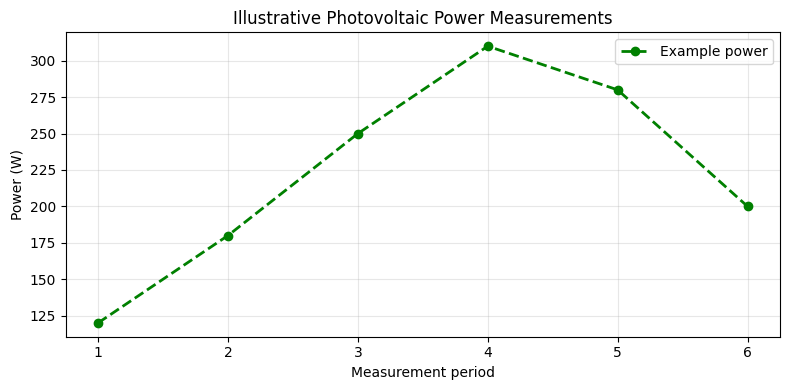

In [ ]:
measurement_periods = np.arange(1, power_w.size + 1)

plt.figure(figsize=(8, 4))
plt.plot(
    measurement_periods,
    power_w,
    color="green",
    linestyle="--",
    linewidth=2,
    marker="o",
    label="Example power",
)
plt.title("Illustrative Photovoltaic Power Measurements")
plt.xlabel("Measurement period")
plt.ylabel("Power (W)")
plt.xticks(measurement_periods)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Create a bar chart
Bar charts compare categories. These three synthetic values represent panel
outputs at the same illustrative instant. Start the vertical axis at zero so
bar lengths give a fair comparison.

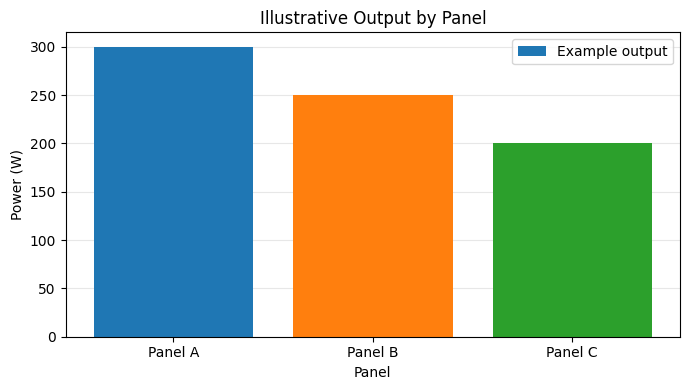

In [ ]:
panel_names = ["Panel A", "Panel B", "Panel C"]
panel_output_w = np.array([300.0, 250.0, 200.0])
chart_colors = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(7, 4))
plt.bar(panel_names, panel_output_w, color=chart_colors, label="Example output")
plt.title("Illustrative Output by Panel")
plt.xlabel("Panel")
plt.ylabel("Power (W)")
plt.ylim(bottom=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

### Create a pie chart
A pie chart shows parts of a meaningful whole. Here it shows each panel's share
of the combined output at the same instant, not energy over time.
Values must be nonnegative and their sum must be positive.

`labels` names the segments, and `autopct` displays percentages.
A pie chart does not need axis labels or a grid.

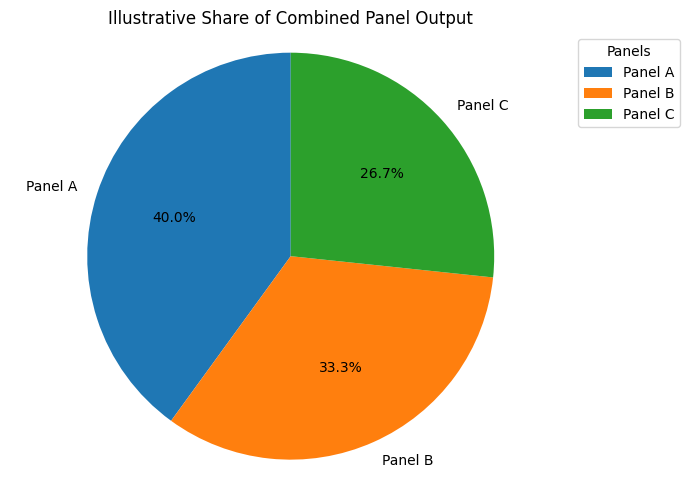

In [ ]:
plt.figure(figsize=(7, 5))
plt.pie(
    panel_output_w,
    labels=panel_names,
    colors=chart_colors,
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Illustrative Share of Combined Panel Output")
plt.legend(title="Panels", loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.axis("equal")
plt.tight_layout()
plt.show()

## 4. pandas: structured data
pandas provides labeled structures for tabular analysis.

- A **Series** is a one-dimensional labeled structure with an index.
- A **DataFrame** is a two-dimensional table with row labels and column names.
  Different columns can have different data types.

### Create a Series
The explicit index below labels each value with its measurement period.
These labels start at 1 even though positional indexing starts at 0.

In [ ]:
power_series = pd.Series(power_w, index=measurement_periods, name="power_w")
display(power_series)
print("Value with label 1:", power_series.loc[1])
print("Value at position 0:", power_series.iloc[0])

,power_w
1,120.0
2,180.0
3,250.0
4,310.0
5,280.0
6,200.0


Value with label 1: 120.0
Value at position 0: 120.0


### Create a DataFrame from a dictionary
Dictionary keys become column names. The array-like values must have matching lengths.
The default row index starts at zero; `measurement_period` is a separate data column.

In [ ]:
monitoring_data = {
    "measurement_period": measurement_periods,
    "power_w": power_w,
    "status": ["Low", "Low", "Normal", "Normal", "Normal", "Normal"],
}
measurements_df = pd.DataFrame(monitoring_data)
display(measurements_df)

,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
2,3,250.0,Normal
3,4,310.0,Normal
4,5,280.0,Normal
5,6,200.0,Normal


### Inspect the table
`head()` and `tail()` show the first and last five rows by default; pass a number
to change the count. `shape` gives `(rows, columns)`, and `columns` lists column names.
`info()` prints column types, non-null counts, and memory information.

`describe()` summarizes numerical columns by default. Its `std` uses `ddof=1`,
unlike NumPy's default `ddof=0`. Summary statistics for period identifiers have
limited analytical meaning; focus on the measured variables.

In [ ]:
display(measurements_df.head())
display(measurements_df.tail(2))
print("Shape:", measurements_df.shape)
print("Columns:", measurements_df.columns.tolist())
measurements_df.info()
display(measurements_df.describe())

,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
2,3,250.0,Normal
3,4,310.0,Normal
4,5,280.0,Normal


,measurement_period,power_w,status
4,5,280.0,Normal
5,6,200.0,Normal


Shape: (6, 3)
Columns: ['measurement_period', 'power_w', 'status']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   measurement_period  6 non-null      int64  
 1   power_w             6 non-null      float64
 2   status              6 non-null      object 
dtypes: float64(1), int64(1), object(1)
memory usage: 276.0+ bytes


,measurement_period,power_w
count,6.000000,6.000000
mean,3.500000,223.333333
std,1.870829,70.047603
min,1.000000,120.000000
25%,2.250000,185.000000
50%,3.500000,225.000000
75%,4.750000,272.500000
max,6.000000,310.000000


### Select columns and filter rows
Single brackets with one column name return a Series. A list of column names
inside brackets returns a DataFrame, even when the list contains only one name.

A comparison creates a Boolean mask; using it inside brackets selects matching
rows. The 250 W threshold below is only an example selection rule.

In [ ]:
display(measurements_df["power_w"])
display(measurements_df[["measurement_period", "power_w"]])

high_power_mask = measurements_df["power_w"] >= 250.0
print("Filter mask:", high_power_mask.tolist())
high_power_df = measurements_df[high_power_mask]
display(high_power_df)

,power_w
0,120.0
1,180.0
2,250.0
3,310.0
4,280.0
5,200.0


,measurement_period,power_w
0,1,120.0
1,2,180.0
2,3,250.0
3,4,310.0
4,5,280.0
5,6,200.0


Filter mask: [False, False, True, True, True, False]


,measurement_period,power_w,status
2,3,250.0,Normal
3,4,310.0,Normal
4,5,280.0,Normal


## 5. Missing values, sorting, and changing data
### Detect and handle missing values
Use a copy so that the original complete measurements remain available.
`np.nan` represents a missing numerical value here.

- `isna()` returns a Boolean table of missing entries.
- `isna().sum()` counts missing entries per column.
- `dropna()` removes rows containing missing values by default.
- `fillna()` replaces missing values using a chosen value or column mapping.

The mean-based replacement below demonstrates syntax, not a recommended universal
imputation strategy. Missing is not the same as zero, and filling values changes
the data. These methods return new tables by default.

In [ ]:
missing_df = measurements_df.copy()
missing_df.loc[2, "power_w"] = np.nan

display(missing_df)
display(missing_df.isna())
print("Missing values per column:")
print(missing_df.isna().sum())

dropped_df = missing_df.dropna()
mean_power_w = missing_df["power_w"].mean()  # Skips missing values by default.
filled_df = missing_df.fillna({"power_w": mean_power_w})

print("Rows after dropping missing values:")
display(dropped_df)
print("Table after illustrative mean replacement:")
display(filled_df)

,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
2,3,NaN,Normal
3,4,310.0,Normal
4,5,280.0,Normal
5,6,200.0,Normal


,measurement_period,power_w,status
0,False,False,False
1,False,False,False
2,False,True,False
3,False,False,False
4,False,False,False
5,False,False,False


Missing values per column:
measurement_period    0
power_w               1
status                0
dtype: int64
Rows after dropping missing values:


,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
3,4,310.0,Normal
4,5,280.0,Normal
5,6,200.0,Normal


Table after illustrative mean replacement:


,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
2,3,218.0,Normal
3,4,310.0,Normal
4,5,280.0,Normal
5,6,200.0,Normal


### Sort rows
`sort_values()` sorts ascending by default. Use `ascending=False` for descending
order. The returned table keeps its original row labels and does not change the
original DataFrame.

In [ ]:
sorted_df = measurements_df.sort_values("power_w", ascending=False)
display(sorted_df)

,measurement_period,power_w,status
3,4,310.0,Normal
4,5,280.0,Normal
2,3,250.0,Normal
5,6,200.0,Normal
1,2,180.0,Low
0,1,120.0,Low


### Add a calculated column and rename a column
Assigning to a new column name adds a column. `rename(columns={...})` returns a
renamed DataFrame by default, so assign the result to keep it.
We work on a copy and keep the original monitoring table unchanged.

In [ ]:
updated_df = measurements_df.copy()
updated_df["power_kw"] = updated_df["power_w"] / 1000.0
updated_df = updated_df.rename(columns={"status": "panel_status"})
display(updated_df)

,measurement_period,power_w,panel_status,power_kw
0,1,120.0,Low,0.12
1,2,180.0,Low,0.18
2,3,250.0,Normal,0.25
3,4,310.0,Normal,0.31
4,5,280.0,Normal,0.28
5,6,200.0,Normal,0.20


## 6. Save and read a CSV file
CSV stores a table as comma-separated text. `to_csv()` writes it and `read_csv()`
reads it into a new DataFrame. Use `index=False` to avoid saving the default row
index as an extra column.

**File effect:** the next cell creates or overwrites only
`07_example_photovoltaic_measurements.csv` in the kernel's current working directory.
The printed absolute path shows where it is saved. Change the filename first if
that location already contains a file you need to keep.

The file is generated learning output and does not need to be committed.
CSV does not preserve all pandas metadata or types; check inferred types after loading.

In [ ]:
csv_path = Path.cwd() / "07_example_photovoltaic_measurements.csv"
measurements_df.to_csv(csv_path, index=False)
print("Saved CSV:", csv_path.resolve())

loaded_df = pd.read_csv(csv_path)
display(loaded_df)
print("Loaded column types:")
print(loaded_df.dtypes)

Saved CSV: /content/07_example_photovoltaic_measurements.csv


,measurement_period,power_w,status
0,1,120.0,Low
1,2,180.0,Low
2,3,250.0,Normal
3,4,310.0,Normal
4,5,280.0,Normal
5,6,200.0,Normal


Loaded column types:
measurement_period      int64
power_w               float64
status                 object
dtype: object


## Summary
| Library | Main operations covered |
| --- | --- |
| NumPy | `array`, `zeros`, `ones`, `arange`, array attributes, indexing, slicing |
| NumPy | `sum`, `min`, `max`, `mean`, `std`, broadcasting, `reshape` |
| Matplotlib | `plot`, `bar`, `pie`, titles, labels, colors, markers, legends, grids |
| pandas | `Series`, `DataFrame`, `head`, `tail`, `info`, `describe` |
| pandas | Column selection, Boolean filtering, `isna`, `dropna`, `fillna` |
| pandas | `sort_values`, calculated columns, `rename`, `to_csv`, `read_csv` |

### Common pitfalls
- Assuming a NumPy slice is an independent copy.
- Reshaping to a shape with a different number of elements.
- Broadcasting arrays whose trailing dimensions are incompatible.
- Providing different numbers of x and y values for a line chart.
- Calling `legend()` without giving the plotted data a label.
- Confusing missing values with measured zeros.
- Forgetting `index=False` when exporting a table without its row index.
- Assuming a relative file path is always relative to the notebook file.